<a href="https://colab.research.google.com/github/sociallyH03ly/Financial-Account-Ownership-Among-Filipino-Adults-Findex-2025-/blob/main/Findex_PH_Account_Ownership_ML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Predicting Formal Financial Account Ownership Among Filipino Adults Using Machine Learning
### The digital financial inclusion gap in the Philippines · Global Findex 2025 microdata (survey year 2024)

**Research problem.** Which socioeconomic characteristics are associated with owning a *formal* financial account?

**Pipeline**
1. Define the target and a **leakage-aware** feature set (some Findex variables are definitionally tied to account ownership)
2. Logistic regression for inference: odds ratios, average marginal effects, likelihood-ratio tests
3. Logistic regression vs Random Forest (plus a baseline and gradient boosting as reference) using repeated, nested cross-validation
4. Feature importance by five complementary methods, combined into a consensus ranking
5. The *gap*: who is least likely to hold an account, and which unbanked adults look most "ready" for inclusion
6. Robustness checks

> **Read this first.** Results describe *statistical association and predictive value*, not causes. With n = 1,000 and a heavily weighted sample (effective n ≈ 430), uncertainty is substantial, so differences smaller than about 0.02 AUC are not meaningful.

## 0. Setup

In [10]:
import os, glob, warnings
os.environ["PYTHONWARNINGS"] = "ignore"   # keeps parallel workers quiet
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from joblib import Parallel, delayed

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, SplineTransformer
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, RandomizedSearchCV
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss, roc_curve, precision_recall_curve
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
from sklearn.calibration import calibration_curve
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50); pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
sns.set_theme(style="whitegrid", context="notebook"); plt.rcParams["figure.dpi"] = 110

SEED = 42
FAST = False          # True = fewer CV repeats / smaller search (quick test run, noisier numbers)
N_REPEATS = 1 if FAST else 3
N_ITER_RF = 4 if FAST else 8

# ---- Data location: upload dialog in Colab, or set DATA_PATH ---------------
DATA_PATH = None
def locate_data():
    if DATA_PATH and os.path.exists(DATA_PATH): return DATA_PATH
    hits = sorted(glob.glob("*Findex*Philippines*.csv") + glob.glob("/content/*Findex*Philippines*.csv"))
    if hits: return hits[0]
    try:
        from google.colab import files
        print("Please select the Findex Philippines CSV file..."); return next(iter(files.upload()))
    except ImportError:
        raise FileNotFoundError("CSV not found. Set DATA_PATH or place the file next to the notebook.")
path = locate_data()
d = pd.read_csv(path, low_memory=False)
print(f"Loaded {path}: {d.shape[0]:,} rows × {d.shape[1]} columns")

Loaded /content/Findex_Microdata_2025_updatePhilippines.csv: 1,000 rows × 199 columns


## 1. Target and features

**Target: `account_fin`** = 1 if the adult has an account at a bank or other formal financial institution (credit union, MFI, cooperative, post office) or a debit card.
Mobile-money-only users are coded 0 here. They are *not* formally banked, and this is exactly where the Philippine "digital" gap sits. (Section 8 repeats the analysis for `account`, which includes mobile money.)

**Leakage control.** Several Findex variables are mechanically linked to account ownership and are *excluded*:

| Excluded variable | Why |
|---|---|
| `dig_account`, `anydigpayment` | Defined *from* account ownership (payments from/into an account) |
| `receive_wages/transfers/pensions/agriculture` = "into an account" | Same: category 1 literally means "into an account" |
| `fin2` (debit card) | Debit card is part of the `account_fin` definition |
| `fin3`–`fin10`, `fin25*`, `fin26*`, … | Asked **only** of account owners: missingness itself reveals the target |
| `saved`, `borrowed`, `domestic_remittances` | Partly constructed from account use |

**Feature sets (cumulative)**
* **A – Socioeconomic:** age, sex, education, income quintile, workforce status, urban/rural, foundational ID ownership
* **B – + Access (primary):** mobile phone, smartphone, internet use
* **C – + Digital behaviour:** breadth of online activities, digital merchant payment (card or phone). *Digital merchant payment can use a debit card, so this set is partially circular; read set C as association, not as a clean predictor.*

In [11]:
yes = lambda col: np.where(d[col].isna(), np.nan, (d[col] == 1).astype(float))

X = pd.DataFrame(index=d.index)
X["age"]           = d["age"].astype(float)
X["female"]        = (d["female"] == 1).astype(int)           # codebook: 1 = female, 2 = male
X["educ"]          = d["educ"].astype(float)                   # 1 primary or less, 2 secondary, 3 tertiary+
X["inc_q"]         = d["inc_q"].astype(float)                  # 1 poorest ... 5 richest
X["in_workforce"]  = (d["emp_in"] == 1).astype(int)
X["urban"]         = (d["urbanicity"] == 2).astype(int)
X["has_id"]        = np.where(d["fin46"] == 1, 1.0, np.where(d["fin46"] == 2, 0.0, np.nan))   # DK/refused -> NaN
X["has_phone"]     = (d["con1"] == 1).astype(int)
X["smartphone"]    = ((d["con1"] == 1) & (d["con9"] == 1)).astype(int)
X["internet_use"]  = d["internet_use"].astype(float)
con30 = ["con30a","con30b","con30c","con30d","con30e","con30f","con30g","con30h"]
X["online_breadth"]= (d[con30] == 1).sum(axis=1).astype(float)  # 0 if not asked (no internet/smartphone)
X["digital_merchant_pay"] = d["merchantpay_dig"].astype(float)

X = X.astype(float)   # float dtype everywhere (needed by partial-dependence plots)
y  = d["account_fin"].astype(int)
y_any = d["account"].astype(int)
w  = d["wgt"].astype(float)

SET_A = ["age","female","educ","inc_q","in_workforce","urban","has_id"]
SET_B = SET_A + ["has_phone","smartphone","internet_use"]
SET_C = SET_B + ["online_breadth","digital_merchant_pay"]
SETS = {"A: Socioeconomic": SET_A, "B: + Access": SET_B, "C: + Digital behaviour": SET_C}
BIN = ["female","in_workforce","urban","has_id","has_phone","smartphone","internet_use","digital_merchant_pay"]
LABELS = {"age":"Age","female":"Female","educ":"Education","inc_q":"Income quintile","in_workforce":"In workforce","urban":"Urban",
          "has_id":"Foundational ID","has_phone":"Mobile phone","smartphone":"Smartphone","internet_use":"Internet use",
          "online_breadth":"Online activity breadth","digital_merchant_pay":"Digital merchant payment"}

print(f"Target prevalence: unweighted {y.mean():.1%} | weighted {np.average(y, weights=w):.1%}   (a no-skill model has AUC 0.50 and PR-AUC ≈ prevalence)")
print("Missing values in features:", X.isna().sum()[X.isna().sum() > 0].to_dict())
display(X.describe().T[["count","mean","std","min","max"]])

Target prevalence: unweighted 33.9% | weighted 33.5%   (a no-skill model has AUC 0.50 and PR-AUC ≈ prevalence)
Missing values in features: {'has_id': 5}


,count,mean,std,min,max
age,"1,000.000",41.506,17.423,15.000,89.000
female,"1,000.000",0.566,0.496,0.000,1.000
educ,"1,000.000",1.698,0.606,1.000,3.000
inc_q,"1,000.000",3.215,1.413,1.000,5.000
in_workforce,"1,000.000",0.569,0.495,0.000,1.000
urban,"1,000.000",0.380,0.486,0.000,1.000
has_id,995.000,0.707,0.456,0.000,1.000
has_phone,"1,000.000",0.798,0.402,0.000,1.000
smartphone,"1,000.000",0.688,0.464,0.000,1.000
internet_use,"1,000.000",0.688,0.464,0.000,1.000


## 2. First look: who has a formal account? (weighted)

variable,group,n,pct_of_sample,formal_account_pct,mobile_money_only_pct
Female,Male,434,49.2,28.3,14.8
Female,Female,566,50.8,38.6,18.5
Education,Primary or less,380,31.8,28.4,5.2
Education,Secondary,542,57.4,30.3,23.0
Education,Tertiary+,78,10.8,65.9,16.3
Income quintile,Q1 poorest,160,19.9,24.7,8.4
Income quintile,Q2,176,20.1,24.2,11.6
Income quintile,Q3,210,19.7,34.8,20.5
Income quintile,Q4,197,20.3,38.3,23.8
Income quintile,Q5 richest,257,19.9,45.6,18.8


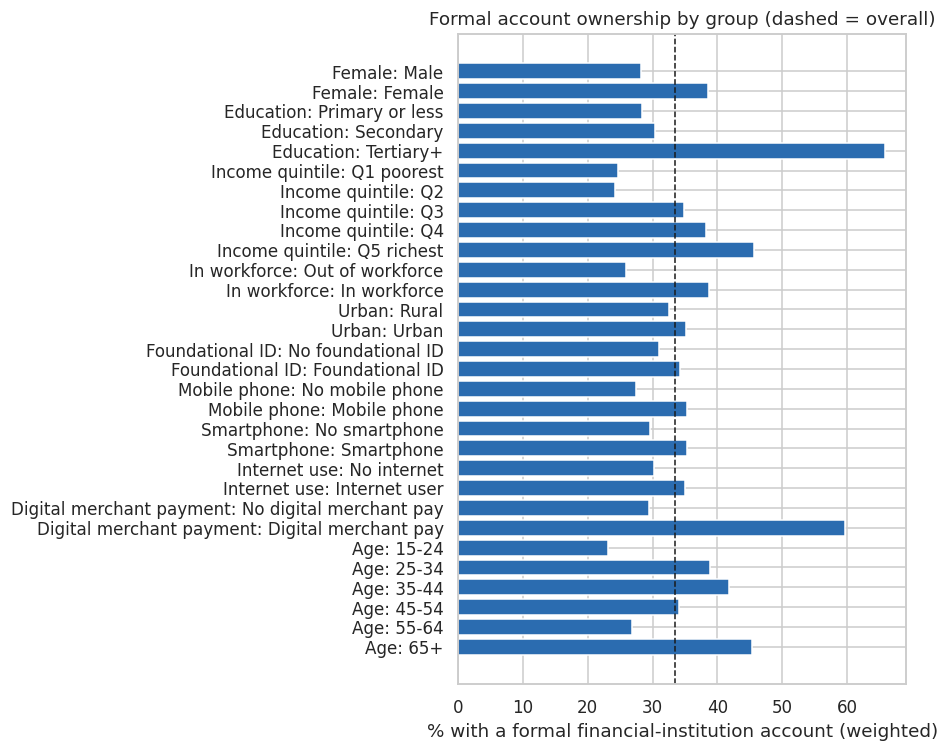

In [12]:
def wmean(v, wt):
    m = ~np.isnan(v); return np.average(v[m], weights=wt[m]) if m.any() else np.nan

rows = []
for var, lv in [("female",{0:"Male",1:"Female"}), ("educ",{1:"Primary or less",2:"Secondary",3:"Tertiary+"}),
                ("inc_q",{1:"Q1 poorest",2:"Q2",3:"Q3",4:"Q4",5:"Q5 richest"}), ("in_workforce",{0:"Out of workforce",1:"In workforce"}),
                ("urban",{0:"Rural",1:"Urban"}), ("has_id",{0:"No foundational ID",1:"Foundational ID"}),
                ("has_phone",{0:"No mobile phone",1:"Mobile phone"}), ("smartphone",{0:"No smartphone",1:"Smartphone"}),
                ("internet_use",{0:"No internet",1:"Internet user"}), ("digital_merchant_pay",{0:"No digital merchant pay",1:"Digital merchant pay"})]:
    for k, name in lv.items():
        m = (X[var] == k).values
        rows.append(dict(variable=LABELS[var], group=name, n=int(m.sum()), pct_of_sample=100*np.average(m, weights=w),
                         formal_account_pct=100*wmean(y.values[m].astype(float), w.values[m]), mobile_money_only_pct=100*wmean(((d.account_mob==1)&(d.account_fin==0)).values[m].astype(float), w.values[m])))
age_grp = pd.cut(X.age, [14,24,34,44,54,64,120], labels=["15-24","25-34","35-44","45-54","55-64","65+"])
for k in age_grp.cat.categories:
    m = (age_grp == k).values
    rows.append(dict(variable="Age", group=k, n=int(m.sum()), pct_of_sample=100*np.average(m, weights=w),
                     formal_account_pct=100*wmean(y.values[m].astype(float), w.values[m]), mobile_money_only_pct=100*wmean(((d.account_mob==1)&(d.account_fin==0)).values[m].astype(float), w.values[m])))
desc = pd.DataFrame(rows)
display(desc.style.format({"pct_of_sample":"{:.1f}","formal_account_pct":"{:.1f}","mobile_money_only_pct":"{:.1f}"}).background_gradient(subset=["formal_account_pct"], cmap="YlGnBu", vmin=0, vmax=100).hide(axis="index"))

fig, ax = plt.subplots(figsize=(8.5, 7))
dd = desc.iloc[::-1]
ax.barh(dd.variable + ": " + dd.group, dd.formal_account_pct, color="#2b6cb0"); ax.set_xlabel("% with a formal financial-institution account (weighted)")
ax.axvline(100*np.average(y, weights=w), color="k", ls="--", lw=1); ax.set_title("Formal account ownership by group (dashed = overall)")
plt.tight_layout(); plt.show()

## 3. Logistic regression for inference (feature set B)
Maximum-likelihood logit on complete cases. Age enters as a quadratic (per 10 years, centred at 40); income and education are categorical (reference = Q1 / primary or less). Odds ratios (OR) > 1 mean higher odds of a formal account, *holding the other variables fixed*.

Complete cases: 995 of 1,000
Pseudo-R² (McFadden): 0.092 | log-likelihood: -577.8 | n = 995


,OR,CI_low,CI_high,p_value
Education: Secondary (vs primary),1.21,0.86,1.70,0.279
Education: Tertiary+ (vs primary),5.34,2.95,9.65,0.000
Income Q2 (vs Q1),0.69,0.42,1.14,0.144
Income Q3 (vs Q1),0.91,0.57,1.48,0.715
Income Q4 (vs Q1),0.85,0.52,1.39,0.518
Income Q5 (vs Q1),1.18,0.73,1.91,0.503
Age (per 10 years),1.26,1.12,1.41,0.000
Age² (per 10y)²,1.02,0.97,1.07,0.463
Female,1.53,1.13,2.06,0.006
In workforce,2.16,1.58,2.96,0.000


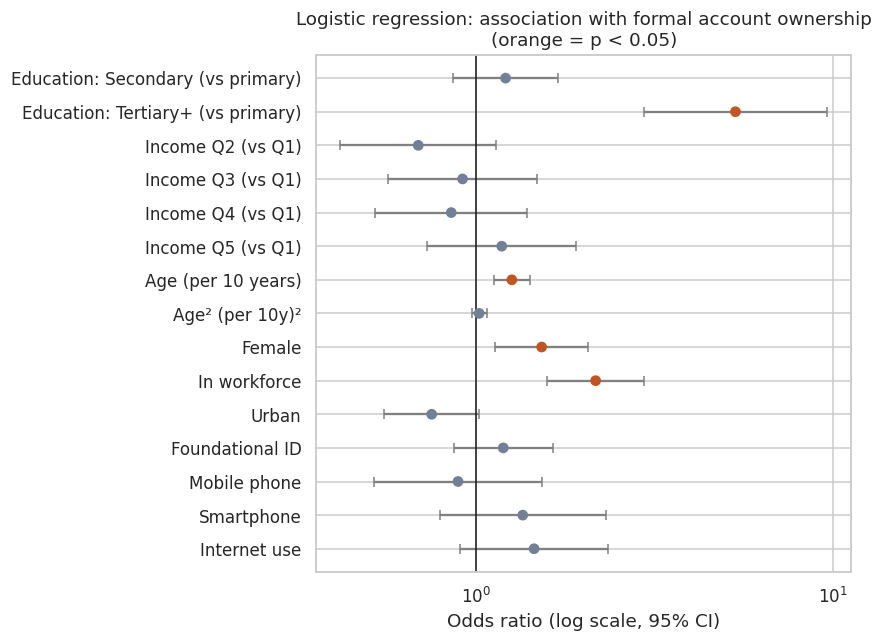

In [13]:
D = X[SET_B].copy(); D["acct"] = y.values; D["wgt"] = w.values
D["age10"] = (D.age - 40) / 10
D = D.dropna()
print(f"Complete cases: {len(D):,} of {len(X):,}")

TERMS = {"Age": "age10 + I(age10**2)", "Female": "female", "Education": "C(educ)", "Income quintile": "C(inc_q)", "In workforce": "in_workforce",
         "Urban": "urban", "Foundational ID": "has_id", "Mobile phone": "has_phone", "Smartphone": "smartphone", "Internet use": "internet_use"}
formula = "acct ~ " + " + ".join(TERMS.values())
logit = smf.logit(formula, data=D).fit(disp=False)
print(f"Pseudo-R² (McFadden): {logit.prsquared:.3f} | log-likelihood: {logit.llf:.1f} | n = {int(logit.nobs)}")

def nice(n):
    n = n.replace("C(educ)[T.2.0]","Education: Secondary (vs primary)").replace("C(educ)[T.3.0]","Education: Tertiary+ (vs primary)")
    for q in (2,3,4,5): n = n.replace(f"C(inc_q)[T.{q}.0]", f"Income Q{q} (vs Q1)")
    return (n.replace("I(age10 ** 2)","Age² (per 10y)²").replace("age10","Age (per 10 years)").replace("female","Female").replace("in_workforce","In workforce")
             .replace("urban","Urban").replace("has_id","Foundational ID").replace("has_phone","Mobile phone").replace("smartphone","Smartphone").replace("internet_use","Internet use"))
ci = logit.conf_int();
orx = pd.DataFrame({"OR": np.exp(logit.params), "CI_low": np.exp(ci[0]), "CI_high": np.exp(ci[1]), "p_value": logit.pvalues}).drop("Intercept")
orx.index = [nice(i) for i in orx.index]
display(orx.style.format({"OR":"{:.2f}","CI_low":"{:.2f}","CI_high":"{:.2f}","p_value":"{:.3f}"}).background_gradient(subset=["OR"], cmap="RdBu_r", vmin=0.2, vmax=5))

fig, ax = plt.subplots(figsize=(8, 6))
o = orx.iloc[::-1]; sig = o.p_value < 0.05
ax.errorbar(o.OR, range(len(o)), xerr=[o.OR-o.CI_low, o.CI_high-o.OR], fmt="none", ecolor="grey", capsize=3)
ax.scatter(o.OR, range(len(o)), c=np.where(sig, "#c05621", "#718096"), zorder=3)
ax.axvline(1, color="k", lw=1); ax.set_xscale("log"); ax.set_yticks(range(len(o))); ax.set_yticklabels(o.index)
ax.set_xlabel("Odds ratio (log scale, 95% CI)"); ax.set_title("Logistic regression: association with formal account ownership\n(orange = p < 0.05)")
plt.tight_layout(); plt.show()

In [14]:
# Average marginal effects (percentage-point change in P(account)) - easier to communicate than odds ratios
ame = logit.get_margeff(at="overall").summary_frame()
ame.index = [nice(i) for i in ame.index]
ame = ame.rename(columns={"dy/dx":"AME","Conf. Int. Low":"CI_low","Cont. Int. Hi.":"CI_high","Pr(>|z|)":"p_value"})
ame[["AME","CI_low","CI_high"]] *= 100
display(ame[["AME","CI_low","CI_high","p_value"]].style.format("{:.1f}", subset=["AME","CI_low","CI_high"]).format("{:.3f}", subset=["p_value"]).background_gradient(subset=["AME"], cmap="RdBu_r", vmin=-30, vmax=30))
print("AME = average change in the probability of a formal account (in percentage points) for a 1-unit change (or 0→1 for dummies).")

,AME,CI_low,CI_high,p_value
Education: Secondary (vs primary),3.7,-3.0,10.5,0.278
Education: Tertiary+ (vs primary),33.1,22.1,44.1,0.000
Income Q2 (vs Q1),-7.4,-17.3,2.5,0.143
Income Q3 (vs Q1),-1.8,-11.2,7.7,0.715
Income Q4 (vs Q1),-3.2,-12.9,6.5,0.518
Income Q5 (vs Q1),3.2,-6.2,12.7,0.503
Age (per 10 years),4.5,2.3,6.8,0.000
Age² (per 10y)²,0.4,-0.6,1.3,0.463
Female,8.3,2.5,14.2,0.005
In workforce,15.2,9.3,21.2,0.000


AME = average change in the probability of a formal account (in percentage points) for a 1-unit change (or 0→1 for dummies).


In [15]:
# Variable importance for the logit: likelihood-ratio test when each variable (group of terms) is dropped
lrt = []
for name, term in TERMS.items():
    rest = " + ".join(v for k, v in TERMS.items() if k != name)
    red = smf.logit("acct ~ " + rest, data=D).fit(disp=False)
    chi2 = 2 * (logit.llf - red.llf); df_ = int(round(logit.df_model - red.df_model))
    lrt.append(dict(variable=name, LR_chi2=chi2, df=df_, p_value=stats.chi2.sf(chi2, df_)))
lrt = pd.DataFrame(lrt).set_index("variable").sort_values("LR_chi2", ascending=False)
display(lrt.style.format({"LR_chi2":"{:.1f}","p_value":"{:.4f}"}).background_gradient(subset=["LR_chi2"], cmap="Oranges"))

# Multicollinearity (VIF) on the design matrix
Xd = pd.get_dummies(D[SET_B].assign(age=D.age), columns=["educ","inc_q"], drop_first=True).astype(float)
Xd = sm.add_constant(Xd)
vif = pd.Series([variance_inflation_factor(Xd.values, i) for i in range(1, Xd.shape[1])], index=Xd.columns[1:]).sort_values(ascending=False)
print("\nVariance inflation factors (VIF > 5 suggests the effect of that variable is hard to separate from others):")
display(vif.to_frame("VIF").T)

,LR_chi2,df,p_value
variable,,,
Education,35.9,2,0.0000
In workforce,24.0,1,0.0000
Age,23.4,2,0.0000
Female,7.8,1,0.0054
Income quintile,6.1,4,0.1891
Urban,3.4,1,0.0638
Internet use,2.4,1,0.1235
Smartphone,1.2,1,0.2692
Foundational ID,1.1,1,0.2839



Variance inflation factors (VIF > 5 suggests the effect of that variable is hard to separate from others):


,smartphone,internet_use,inc_q_5.0,has_phone,inc_q_4.0,inc_q_3.0,inc_q_2.0,age,educ_2.0,educ_3.0,urban,female,in_workforce,has_id
VIF,3.013,2.442,2.320,2.305,1.947,1.937,1.765,1.592,1.465,1.292,1.108,1.105,1.100,1.037


In [16]:
# Sensitivity: survey-weighted logit with heteroskedasticity-robust SEs (weights rescaled to mean 1; no strata/PSU available)
Dw = D.copy(); Dw["wn"] = Dw.wgt / Dw.wgt.mean()
glm = smf.glm(formula, data=Dw, family=sm.families.Binomial(), freq_weights=Dw.wn).fit(cov_type="HC1")
cmp_ = pd.DataFrame({"OR_unweighted": np.exp(logit.params), "OR_weighted": np.exp(glm.params), "p_unweighted": logit.pvalues, "p_weighted": glm.pvalues}).drop("Intercept")
cmp_.index = [nice(i) for i in cmp_.index]
display(cmp_.style.format({"OR_unweighted":"{:.2f}","OR_weighted":"{:.2f}","p_unweighted":"{:.3f}","p_weighted":"{:.3f}"}))
flips = cmp_[((cmp_.p_unweighted < .05) != (cmp_.p_weighted < .05))]
print("Terms whose significance (5%) changes with weighting:", list(flips.index) if len(flips) else "none")

,OR_unweighted,OR_weighted,p_unweighted,p_weighted
Education: Secondary (vs primary),1.21,1.19,0.279,0.340
Education: Tertiary+ (vs primary),5.34,4.46,0.000,0.000
Income Q2 (vs Q1),0.69,0.72,0.144,0.197
Income Q3 (vs Q1),0.91,1.15,0.715,0.557
Income Q4 (vs Q1),0.85,1.43,0.518,0.131
Income Q5 (vs Q1),1.18,1.84,0.503,0.014
Age (per 10 years),1.26,1.32,0.000,0.000
Age² (per 10y)²,1.02,0.99,0.463,0.743
Female,1.53,1.85,0.006,0.000
In workforce,2.16,1.73,0.000,0.001


Terms whose significance (5%) changes with weighting: ['Income Q5 (vs Q1)']


## 4. Model comparison: Logistic Regression vs Random Forest
**Design:** 5-fold stratified cross-validation repeated 3 times (15 held-out folds). All models see the *same* folds, so differences are paired.
Hyper-parameters are tuned **inside** each training fold (nested CV), so the reported scores are not inflated by tuning.

* **Dummy:** predicts the base rate (reference, AUC 0.5)
* **Logistic regression:** L2-penalised, penalty tuned by CV; age enters through a spline so non-linearity is allowed
* **Random Forest:** 300 trees; depth, leaf size and `max_features` tuned by randomised search
* **Gradient boosting:** a reference point (fixed, conservative settings)

Metrics: **ROC-AUC** (ranking quality), **PR-AUC** (precision/recall for the minority class), **Brier score** (probability accuracy; lower is better). *Wtd. AUC* weights test observations by `wgt` to reflect the population.

In [ ]:
def make_pre(kind, cols):
    num_extra = [c for c in ["inc_q","online_breadth"] if c in cols]
    bins = [c for c in BIN if c in cols]
    if kind == "lr":
        tr = []
        if "age" in cols:
            tr.append(("age", Pipeline([("i", SimpleImputer(strategy="median")), ("s", SplineTransformer(n_knots=4, degree=3, include_bias=False)), ("z", StandardScaler())]), ["age"]))
        if num_extra: tr.append(("num", Pipeline([("i", SimpleImputer(strategy="median")), ("z", StandardScaler())]), num_extra))
        if bins:      tr.append(("bin", Pipeline([("i", SimpleImputer(strategy="most_frequent")), ("z", StandardScaler())]), bins))
        if "educ" in cols: tr.append(("educ", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False), ["educ"]))
        return ColumnTransformer(tr)
    return ColumnTransformer([("all", SimpleImputer(strategy="median"), list(cols))])

RF_GRID = {"clf__max_depth":[3,5,8,None], "clf__min_samples_leaf":[1,3,5,10,20], "clf__max_features":["sqrt",0.5,1.0]}

def make_model(kind, cols, seed=SEED, tune=True, params=None):
    params = params or {}
    if kind == "dummy":
        return Pipeline([("clf", DummyClassifier(strategy="prior"))])
    if kind == "lr":
        clf = LogisticRegressionCV(Cs=np.logspace(-2, 1, 8), cv=5, scoring="roc_auc", max_iter=3000) if tune else LogisticRegression(C=params.get("C", 1.0), max_iter=3000)
        return Pipeline([("pre", make_pre("lr", cols)), ("clf", clf)])
    if kind == "rf":
        base = Pipeline([("pre", make_pre("rf", cols)), ("clf", RandomForestClassifier(n_estimators=300, random_state=seed, n_jobs=1, **{k.replace("clf__",""):v for k,v in params.items()}))])
        if tune:
            return RandomizedSearchCV(base, RF_GRID, n_iter=N_ITER_RF, cv=3, scoring="roc_auc", random_state=seed, n_jobs=1)
        return base
    if kind == "gb":
        return Pipeline([("clf", HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=150, l2_regularization=1.0, min_samples_leaf=20, random_state=seed))])
    raise ValueError(kind)

NAMES = {"dummy":"Baseline (prior)", "lr":"Logistic regression", "rf":"Random Forest", "gb":"Gradient boosting (ref.)"}

def run_cv(kind, cols, target=y, train_w=None, n_repeats=N_REPEATS, tune=True, params=None, seed=SEED):
    cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=n_repeats, random_state=seed)
    splits = list(cv.split(X, target))
    def one(k, tr, te):
        m = make_model(kind, cols, seed + k, tune, params)
        kw = {"clf__sample_weight": train_w.iloc[tr].values} if train_w is not None else {}
        m.fit(X.iloc[tr][cols] if kind != "dummy" else X.iloc[tr][cols], target.iloc[tr], **kw)
        p = m.predict_proba(X.iloc[te][cols])[:, 1]; yt = target.iloc[te]
        return k, te, p, dict(fold=k, repeat=k // 5, auc=roc_auc_score(yt, p), pr_auc=average_precision_score(yt, p),
                              brier=brier_score_loss(yt, p), wauc=roc_auc_score(yt, p, sample_weight=w.iloc[te]))
    res = Parallel(n_jobs=-1)(delayed(one)(k, tr, te) for k, (tr, te) in enumerate(splits))
    folds = pd.DataFrame([r[3] for r in res])
    oof = np.full((n_repeats, len(X)), np.nan)
    for k, te, p, _ in res: oof[k // 5, te] = p
    return folds, oof.mean(axis=0)

import time; t0 = time.time()
results, oofs = {}, {}
for sname, cols in SETS.items():
    for kind in ["dummy","lr","rf","gb"]:
        results[(sname, kind)], oofs[(sname, kind)] = run_cv(kind, cols)
    print(f"{sname:26s} done  ({time.time()-t0:,.0f}s elapsed)")

In [ ]:
summ = pd.concat({k: v[["auc","pr_auc","brier","wauc"]].agg(["mean","std"]).T.stack() for k, v in results.items()}, axis=1).T
tab = pd.DataFrame({(f"{a}"): {} for a in []})
rows = []
for (s, k), f in results.items():
    rows.append(dict(feature_set=s, model=NAMES[k], AUC=f.auc.mean(), AUC_sd=f.auc.std(), PR_AUC=f.pr_auc.mean(), Brier=f.brier.mean(), weighted_AUC=f.wauc.mean()))
cmp = pd.DataFrame(rows)
display(cmp.style.format({"AUC":"{:.3f}","AUC_sd":"{:.3f}","PR_AUC":"{:.3f}","Brier":"{:.3f}","weighted_AUC":"{:.3f}"}).background_gradient(subset=["AUC"], cmap="YlGn", vmin=.5, vmax=.9).hide(axis="index"))
print(f"Reference: base rate (PR-AUC of a no-skill model) = {y.mean():.3f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
pl = pd.concat([f.assign(feature_set=s, model=NAMES[k]) for (s, k), f in results.items() if k != "dummy"])
sns.boxplot(data=pl, x="feature_set", y="auc", hue="model", ax=axes[0]); axes[0].set_title("Cross-validated ROC-AUC (15 held-out folds)"); axes[0].set_xlabel(""); axes[0].set_ylabel("AUC"); axes[0].legend(title="", fontsize=8)
sns.boxplot(data=pl, x="feature_set", y="brier", hue="model", ax=axes[1]); axes[1].set_title("Brier score (lower = better calibrated probabilities)"); axes[1].set_xlabel(""); axes[1].get_legend().remove()
plt.tight_layout(); plt.show()

In [ ]:
# Is the difference between LR and RF real? Corrected resampled t-test (Nadeau & Bengio 2003) on paired fold AUCs
def corrected_t(a, b, test_frac=0.25):
    dif = np.asarray(a) - np.asarray(b); n = len(dif)
    var = dif.var(ddof=1) * (1/n + test_frac/(1-test_frac))
    t = dif.mean() / np.sqrt(var) if var > 0 else np.nan
    return dif.mean(), t, 2 * stats.t.sf(abs(t), n-1)

rows = []
for s in SETS:
    for a, b in [("rf","lr"), ("gb","lr"), ("rf","gb")]:
        m, t, p = corrected_t(results[(s,a)].auc, results[(s,b)].auc)
        rows.append(dict(feature_set=s, comparison=f"{NAMES[a]} − {NAMES[b]}", mean_AUC_diff=m, t=t, p_value=p))
display(pd.DataFrame(rows).style.format({"mean_AUC_diff":"{:+.3f}","t":"{:.2f}","p_value":"{:.3f}"}).hide(axis="index"))
print("A positive difference favours the first model. Differences with p > 0.05 mean the models are statistically indistinguishable here.")

# Does adding information help? (LR, paired across the same folds)
for a, b in [("B: + Access","A: Socioeconomic"), ("C: + Digital behaviour","B: + Access")]:
    for k in ("lr","rf"):
        m, t, p = corrected_t(results[(a,k)].auc, results[(b,k)].auc)
        print(f"{NAMES[k]:22s} {a} vs {b}: ΔAUC = {m:+.3f}  (p = {p:.3f})")

In [ ]:
# ROC / precision-recall / calibration on out-of-fold predictions (feature set B, the primary set)
S = "B: + Access"
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for kind, col in [("lr","#2b6cb0"),("rf","#c05621"),("gb","#718096")]:
    p = oofs[(S, kind)]
    fpr, tpr, _ = roc_curve(y, p); axes[0].plot(fpr, tpr, color=col, label=f"{NAMES[kind]} (AUC {roc_auc_score(y,p):.3f})")
    pr, rc, _ = precision_recall_curve(y, p); axes[1].plot(rc, pr, color=col, label=f"{NAMES[kind]} (AP {average_precision_score(y,p):.3f})")
    fp, mp = calibration_curve(y, p, n_bins=8, strategy="quantile"); axes[2].plot(mp, fp, "o-", color=col, label=NAMES[kind])
axes[0].plot([0,1],[0,1],"k--",lw=1); axes[0].set_title("ROC curve (out-of-fold)"); axes[0].set_xlabel("False positive rate"); axes[0].set_ylabel("True positive rate"); axes[0].legend(fontsize=8)
axes[1].axhline(y.mean(), color="k", ls="--", lw=1); axes[1].set_title("Precision–recall curve"); axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision"); axes[1].legend(fontsize=8)
axes[2].plot([0,1],[0,1],"k--",lw=1); axes[2].set_title("Calibration"); axes[2].set_xlabel("Mean predicted probability"); axes[2].set_ylabel("Observed share with account"); axes[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 5. Which characteristics matter most? Feature importance
No single importance measure is reliable on its own: impurity importance is biased toward many-valued features, permutation importance splits credit among correlated features, and coefficients depend on scaling. So I use **five complementary measures** on feature set B and look for agreement:

1. **Logit LR-test** χ² (Section 3)
2. **Permutation importance, Logistic regression** (drop in held-out AUC when a variable is shuffled)
3. **Permutation importance, Random Forest**
4. **Drop-variable ablation, Random Forest** (refit without the variable; the AUC loss)
5. **Random Forest impurity (MDI) importance** (for comparison, known to be biased)

In [ ]:
COLS = SET_B
# Fixed hyper-parameters from a single tuning on the full data (used only for importance / PDP / robustness)
rf_search = make_model("rf", COLS).fit(X[COLS], y); rf_params = rf_search.best_params_
lr_cv = make_model("lr", COLS).fit(X[COLS], y); lr_C = float(lr_cv.named_steps["clf"].C_[0])
print("RF params:", {k.replace("clf__",""): v for k, v in rf_params.items()}, "| LR C:", round(lr_C, 3))
PARAMS = {"rf": rf_params, "lr": {"C": lr_C}}

def perm_imp(kind, cols, n_repeats=2):
    cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=n_repeats, random_state=SEED)
    def one(k, tr, te):
        m = make_model(kind, cols, SEED + k, False, PARAMS[kind]).fit(X.iloc[tr][cols], y.iloc[tr])
        pi = permutation_importance(m, X.iloc[te][cols], y.iloc[te], scoring="roc_auc", n_repeats=10, random_state=SEED + k)
        return pi.importances_mean
    out = Parallel(n_jobs=-1)(delayed(one)(k, tr, te) for k, (tr, te) in enumerate(cv.split(X, y)))
    return pd.DataFrame(out, columns=cols)

def drop_col(kind, cols, n_repeats=2):
    base = run_cv(kind, cols, n_repeats=n_repeats, tune=False, params=PARAMS[kind])[0].auc
    out = {}
    for c in cols:
        f = run_cv(kind, [x for x in cols if x != c], n_repeats=n_repeats, tune=False, params=PARAMS[kind])[0].auc
        out[c] = (base - f).values
    return pd.DataFrame(out), base

pi_lr, pi_rf = perm_imp("lr", COLS), perm_imp("rf", COLS)
dc_rf, base_rf = drop_col("rf", COLS)
mdi = pd.Series(rf_search.best_estimator_.named_steps["clf"].feature_importances_, index=COLS)
print("done")

In [ ]:
lrt_by_col = pd.Series({"age":lrt.loc["Age","LR_chi2"], "female":lrt.loc["Female","LR_chi2"], "educ":lrt.loc["Education","LR_chi2"], "inc_q":lrt.loc["Income quintile","LR_chi2"],
                        "in_workforce":lrt.loc["In workforce","LR_chi2"], "urban":lrt.loc["Urban","LR_chi2"], "has_id":lrt.loc["Foundational ID","LR_chi2"],
                        "has_phone":lrt.loc["Mobile phone","LR_chi2"], "smartphone":lrt.loc["Smartphone","LR_chi2"], "internet_use":lrt.loc["Internet use","LR_chi2"]})
imp = pd.DataFrame({"Logit LR-test χ²": lrt_by_col, "Permutation: LR": pi_lr.mean(), "Permutation: RF": pi_rf.mean(),
                    "Drop-variable: RF": dc_rf.mean(), "RF impurity (MDI)": mdi})
imp.index = [LABELS[c] for c in imp.index]
ranks = imp.rank(ascending=False)
ranks["Mean rank"] = ranks.mean(axis=1)
consensus = ranks.sort_values("Mean rank")
display(consensus.style.format("{:.1f}").background_gradient(cmap="RdYlGn_r", subset=imp.columns, vmin=1, vmax=len(imp)).background_gradient(subset=["Mean rank"], cmap="Blues_r"))
print("Rank 1 = most important. Agreement between methods (Spearman ρ of ranks):")
display(ranks[imp.columns].corr(method="spearman").style.format("{:.2f}").background_gradient(cmap="Greens", vmin=0, vmax=1))

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4.8))
for ax, (title, df_, color) in zip(axes, [("Permutation importance – LR\n(ΔAUC)", pi_lr, "#2b6cb0"), ("Permutation importance – RF\n(ΔAUC)", pi_rf, "#c05621"),
                                         ("Drop-variable ablation – RF\n(ΔAUC when removed)", dc_rf, "#2f855a"), ("RF impurity (MDI)", None, "#718096")]):
    if df_ is not None:
        m = df_.mean().sort_values(); se = (df_.std() / np.sqrt(len(df_))).reindex(m.index)
        ax.barh([LABELS[c] for c in m.index], m.values, xerr=1.96*se.values, color=color, capsize=2)
    else:
        m = mdi.sort_values(); ax.barh([LABELS[c] for c in m.index], m.values, color=color)
    ax.set_title(title, fontsize=10); ax.axvline(0, color="k", lw=.8)
    if ax is not axes[0]: ax.set_yticklabels([LABELS[c] for c in m.index], fontsize=8)
plt.tight_layout(); plt.show()

In [ ]:
# Shape of the relationships (Random Forest partial dependence, set B)
rf_full = make_model("rf", COLS, tune=False, params=PARAMS["rf"]).fit(X[COLS], y)
feats = ["age","inc_q","educ","has_id","internet_use","has_phone"]
fig, ax = plt.subplots(1, len(feats), figsize=(18, 3.4), sharey=True)
PartialDependenceDisplay.from_estimator(rf_full, X[COLS], feats, kind="average", grid_resolution=20, ax=ax, line_kw={"color":"#c05621"})
for a, f in zip(ax, feats): a.set_xlabel(LABELS[f]); a.set_ylabel("P(formal account)" if a is ax[0] else "")
plt.suptitle("Partial dependence (Random Forest): average predicted probability as one variable changes", y=1.03); plt.tight_layout(); plt.show()

## 6. The gap: who is least likely to hold an account, and who is closest?
Predictions below are **out-of-fold** (each adult is scored by a model that never saw them), averaged over repeats. Weighted figures use `wgt`.

In [ ]:
means = {k: results[(S, k)].auc.mean() for k in ("lr","rf")}
best = max(means, key=means.get); print(f"Best of LR/RF by mean CV AUC on set B: {NAMES[best]} ({means[best]:.3f}); LR {means['lr']:.3f} | RF {means['rf']:.3f}")
p = pd.Series(oofs[(S, best)], index=X.index, name="p_account")

G = X.assign(p=p, y=y, w=w, any_mm=((d.account_mob==1)&(d.account_fin==0)).astype(int))
G["propensity_quintile"] = pd.qcut(G.p, 5, labels=["Q1 lowest","Q2","Q3","Q4","Q5 highest"])
def wavg(g, c): return np.average(g[c], weights=g.w)
prof = G.groupby("propensity_quintile", observed=True).apply(lambda g: pd.Series({
    "share_of_adults_%": 100*g.w.sum()/G.w.sum(), "predicted_%": 100*wavg(g,"p"), "observed_account_%": 100*wavg(g,"y"),
    "age": wavg(g,"age"), "female_%": 100*wavg(g,"female"), "income_quintile": wavg(g,"inc_q"), "tertiary_%": 100*np.average(g.educ==3, weights=g.w),
    "in_workforce_%": 100*wavg(g,"in_workforce"), "urban_%": 100*wavg(g,"urban"), "has_ID_%": 100*np.nanmean(g.has_id) , "phone_%": 100*wavg(g,"has_phone"),
    "internet_%": 100*wavg(g,"internet_use"), "mobile_money_only_%": 100*wavg(g,"any_mm")}))
display(prof.T.style.format("{:.1f}").background_gradient(axis=1, cmap="Blues"))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
prof[["predicted_%","observed_account_%"]].plot.bar(ax=ax[0], rot=0, color=["#a0aec0","#2b6cb0"]); ax[0].set_ylabel("%"); ax[0].set_title("Predicted vs observed account ownership by propensity quintile (weighted)"); ax[0].set_xlabel("")
sns.histplot(data=G, x="p", hue=G.y.map({0:"No formal account",1:"Formal account"}), bins=30, stat="density", common_norm=False, ax=ax[1]); ax[1].set_title("Out-of-fold predicted probability"); ax[1].set_xlabel("Predicted P(formal account)")
plt.tight_layout(); plt.show()

In [ ]:
# Segmenting the unbanked: "near-ready" (profile resembles account holders) vs "far" (profile resembles the most excluded)
U = G[G.y == 0].copy()
cut = U.p.quantile(2/3)
U["segment"] = np.where(U.p >= cut, "Near-ready (top third by propensity)", np.where(U.p <= U.p.quantile(1/3), "Furthest (bottom third)", "Middle"))
seg = U.groupby("segment").apply(lambda g: pd.Series({
    "n": len(g), "share_of_unbanked_%": 100*g.w.sum()/U.w.sum(), "mean_predicted_%": 100*wavg(g,"p"),
    "age": wavg(g,"age"), "female_%": 100*wavg(g,"female"), "income_quintile": wavg(g,"inc_q"), "tertiary_%": 100*np.average(g.educ==3, weights=g.w),
    "in_workforce_%": 100*wavg(g,"in_workforce"), "urban_%": 100*wavg(g,"urban"), "has_ID_%": 100*np.nanmean(g.has_id), "phone_%": 100*wavg(g,"has_phone"),
    "internet_%": 100*wavg(g,"internet_use"), "mobile_money_only_%": 100*wavg(g,"any_mm")}))
display(seg.T.style.format("{:.1f}"))
unb_share = U.w.sum() / G.w.sum(); pop = float(d.pop_adult.iloc[0])
print(f"Without a formal account: {unb_share:.1%} of adults ≈ {unb_share*pop/1e6:.1f} million (of {pop/1e6:.1f}M adults aged 15+, WDI 2023).")
nr = U[U.segment.str.startswith("Near")]
print(f"The 'near-ready' third ≈ {nr.w.sum()/G.w.sum()*pop/1e6:.1f} million adults (model-based approximation; they look like account holders on observed traits but do not hold an account).")

In [ ]:
# Does the model perform equally well for different groups? (AUC within subgroup, out-of-fold)
rows = []
for name, mask in [("Female", X.female==1), ("Male", X.female==0), ("Urban", X.urban==1), ("Rural", X.urban==0), ("Primary or less", X.educ==1),
                   ("Secondary", X.educ==2), ("Tertiary+", X.educ==3), ("Income Q1-Q2", X.inc_q<=2), ("Income Q3-Q5", X.inc_q>=3), ("Age 15-34", X.age<35), ("Age 35+", X.age>=35)]:
    m = mask.values
    rows.append(dict(subgroup=name, n=int(m.sum()), formal_account_rate_pct=100*y[m].mean(), AUC=roc_auc_score(y[m], p[m]) if 0 < y[m].mean() < 1 else np.nan))
display(pd.DataFrame(rows).style.format({"formal_account_rate_pct":"{:.1f}","AUC":"{:.3f}"}).hide(axis="index"))

## 7. Robustness checks
Same cross-validation protocol with fixed (pre-tuned) hyper-parameters, so these are comparable with each other but slightly different from the nested results in Section 4.

In [ ]:
def both(label, cols, target=y, train_w=None):
    r = {}
    for k in ("lr","rf"):
        f, _ = run_cv(k, cols, target=target, train_w=train_w, tune=False, params=PARAMS[k]); r[k] = f.auc.mean()
    return dict(variant=label, LR_AUC=r["lr"], RF_AUC=r["rf"])

rob = [both("Reference: set B, target = formal account", SET_B),
       both("Set A only (no phone/internet)", SET_A),
       both("Set C (adds digital behaviour, partly circular)", SET_C),
       both("Set B without foundational ID", [c for c in SET_B if c != "has_id"]),
       both("Set B, trained with survey weights", SET_B, train_w=w),
       both("Set B, target = ANY account (incl. mobile money)", SET_B, target=y_any)]
rob = pd.DataFrame(rob)
display(rob.style.format({"LR_AUC":"{:.3f}","RF_AUC":"{:.3f}"}).hide(axis="index").background_gradient(subset=["LR_AUC","RF_AUC"], cmap="YlGn", vmin=.6, vmax=.85))

In [ ]:
# Do the odds ratios change when the target includes mobile money?
D2 = D.copy(); D2["acct"] = y_any.loc[D2.index].values
logit2 = smf.logit(formula, data=D2).fit(disp=False)
c2 = pd.DataFrame({"OR: formal account": np.exp(logit.params), "OR: any account (incl. mobile money)": np.exp(logit2.params),
                   "p: formal": logit.pvalues, "p: any": logit2.pvalues}).drop("Intercept")
c2.index = [nice(i) for i in c2.index]
display(c2.style.format({"OR: formal account":"{:.2f}","OR: any account (incl. mobile money)":"{:.2f}","p: formal":"{:.3f}","p: any":"{:.3f}"}))
print("Compare: variables whose OR differs most are those separating formal-bank users from mobile-money users.")